In [1]:
from mlp import MLP
import torch
import torch.nn as nn
import random
import matplotlib.pyplot as plt
import torch.nn.functional as f

words=open("data/indian_cities.txt").read().splitlines()
words=[w for w in words if len(w)<20]

words = [w.strip().lower() for w in words]
words=[w for w in words if "(" not in w and ")" not in w]


chars=sorted(list(set("".join(words))))
stoi={s:i+1 for i,s in enumerate(chars)}
stoi["."]=0
itos={i:s for s,i in stoi.items()}



In [2]:
#dividing into training, dev(hyperparameter experiments) and testing
n=len(words)
n1=int(0.8*n)
n2=int(0.9*n)
train_words = words[:n1]
dev_words = words[n1:n2]
test_words = words[n2:]


# 2. Function to create X and Y
block_size = 3

def build_dataset(words):

    X, Y = [], []

    for w in words:
        context = [0] * block_size

        for ch in w + '.':
            ix = stoi[ch]

            X.append(context)
            Y.append(ix)

            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)

    return X, Y


# 3. Create separate datasets
Xtr, Ytr = build_dataset(train_words)
Xdev, Ydev = build_dataset(dev_words)
Xte, Yte = build_dataset(test_words)


0: 3.4118 (0.001000)
1: 3.4114 (0.001007)
2: 3.4110 (0.001014)
3: 3.4107 (0.001021)
4: 3.4103 (0.001028)
5: 3.4099 (0.001035)
6: 3.4095 (0.001042)
7: 3.4092 (0.001050)
8: 3.4088 (0.001057)
9: 3.4084 (0.001064)
10: 3.4080 (0.001072)
11: 3.4076 (0.001079)
12: 3.4072 (0.001087)
13: 3.4069 (0.001094)
14: 3.4065 (0.001102)
15: 3.4061 (0.001109)
16: 3.4057 (0.001117)
17: 3.4053 (0.001125)
18: 3.4049 (0.001133)
19: 3.4044 (0.001140)
20: 3.4040 (0.001148)
21: 3.4036 (0.001156)
22: 3.4032 (0.001164)
23: 3.4028 (0.001172)
24: 3.4024 (0.001181)
25: 3.4019 (0.001189)
26: 3.4015 (0.001197)
27: 3.4011 (0.001205)
28: 3.4007 (0.001214)
29: 3.4002 (0.001222)
30: 3.3998 (0.001231)
31: 3.3993 (0.001239)
32: 3.3989 (0.001248)
33: 3.3984 (0.001256)
34: 3.3980 (0.001265)
35: 3.3975 (0.001274)
36: 3.3971 (0.001283)
37: 3.3966 (0.001292)
38: 3.3962 (0.001301)
39: 3.3957 (0.001310)
40: 3.3952 (0.001319)
41: 3.3948 (0.001328)
42: 3.3943 (0.001337)
43: 3.3938 (0.001346)
44: 3.3933 (0.001356)
45: 3.3929 (0.001365

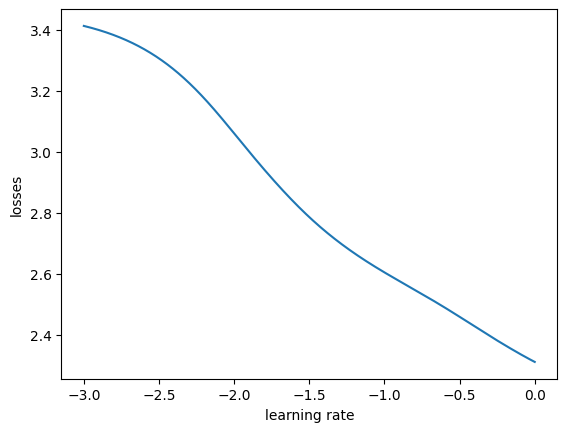

In [22]:
modelA=MLP(emb_dim=3,hidden_size=100)
# finding the suitable learning rate for the model

num=torch.linspace(-3,0,1000)
lr_list=10**num


optimizer = torch.optim.SGD(
    modelA.parameters(),
    lr=0.01
)

losses = []


for i, lr in enumerate(lr_list):

    optimizer.param_groups[0]['lr'] = lr.item()

    optimizer.zero_grad()

    logits = modelA(Xtr)
    loss = f.cross_entropy(logits, Ytr)

    loss.backward()
    optimizer.step()
    print(f"{i}: {loss.item():.4f} ({lr:.6f})")

    losses.append(loss.item())

plt.plot(num, losses)
plt.ylabel("losses")
plt.xlabel("learning rate")
plt.show()













In [5]:
#now we got the range - .1 to 1
#testing independent models on this range

lr_exponents=torch.linspace(-1,0,50)
new_lr_list=10**lr_exponents

results = []

for lr in new_lr_list:

    # Fresh model for every learning rate
    model = MLP(emb_dim=3, hidden_size=100)

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr.item()
    )

    for i in range(1000):

        logits = model(Xtr)
        loss = f.cross_entropy(logits, Ytr)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Evaluate final training loss
    with torch.no_grad():
        final_loss = f.cross_entropy(model(Xtr), Ytr)

    results.append((lr.item(), final_loss.item()))

    print(f"LR: {lr.item():.4f}, Loss: {final_loss.item():.4f}")


LR: 0.1000, Loss: 2.4064
LR: 0.1048, Loss: 2.3569
LR: 0.1099, Loss: 2.3878
LR: 0.1151, Loss: 2.3802
LR: 0.1207, Loss: 2.3485
LR: 0.1265, Loss: 2.3310
LR: 0.1326, Loss: 2.3474
LR: 0.1389, Loss: 2.3333
LR: 0.1456, Loss: 2.3274
LR: 0.1526, Loss: 2.3031
LR: 0.1600, Loss: 2.3213
LR: 0.1677, Loss: 2.2943
LR: 0.1758, Loss: 2.2877
LR: 0.1842, Loss: 2.3211
LR: 0.1931, Loss: 2.2868
LR: 0.2024, Loss: 2.2693
LR: 0.2121, Loss: 2.2661
LR: 0.2223, Loss: 2.2705
LR: 0.2330, Loss: 2.2614
LR: 0.2442, Loss: 2.2471
LR: 0.2560, Loss: 2.2470
LR: 0.2683, Loss: 2.2378
LR: 0.2812, Loss: 2.2287
LR: 0.2947, Loss: 2.2357
LR: 0.3089, Loss: 2.2486
LR: 0.3237, Loss: 2.2338
LR: 0.3393, Loss: 2.2232
LR: 0.3556, Loss: 2.2184
LR: 0.3728, Loss: 2.2044
LR: 0.3907, Loss: 2.1803
LR: 0.4095, Loss: 2.1962
LR: 0.4292, Loss: 2.1949
LR: 0.4498, Loss: 2.1997
LR: 0.4715, Loss: 2.1933
LR: 0.4942, Loss: 2.1652
LR: 0.5179, Loss: 2.2000
LR: 0.5429, Loss: 2.1642
LR: 0.5690, Loss: 2.1425
LR: 0.5964, Loss: 2.1592
LR: 0.6251, Loss: 2.1505


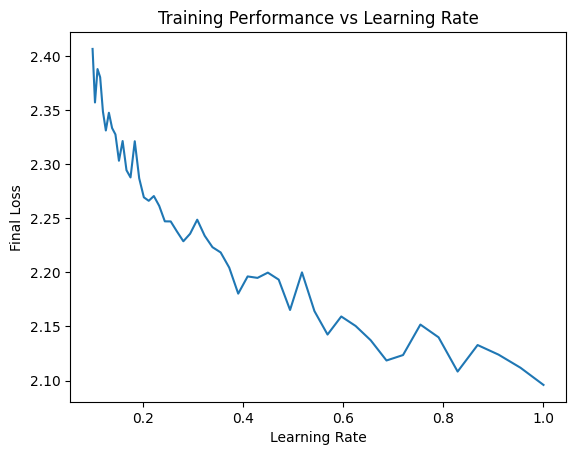

In [6]:
plt.plot([r[0] for r in results], [r[1] for r in results])
plt.xlabel("Learning Rate")
plt.ylabel("Final Loss")
plt.title("Training Performance vs Learning Rate")
plt.show()

In [ ]:
lr_exponents = torch.linspace(0, 0.7, 30)
new_lr_list = 10**lr_exponents
dev_losses = []

results = []

for lr in new_lr_list:

    # Fresh model for every learning rate
    model = MLP(emb_dim=3, hidden_size=100)

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr.item()
    )

    for i in range(1000):

        logits = model(Xtr)
        loss = f.cross_entropy(logits, Ytr)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Evaluate final training loss
    with torch.no_grad():
        final_loss = f.cross_entropy(model(Xtr), Ytr)

    results.append((lr.item(), final_loss.item()))

    print(f"LR: {lr.item():.4f}, Loss: {final_loss.item():.4f}")
    logits_dev = model(Xdev)
    dev_loss = f.cross_entropy(logits_dev, Ydev)
    dev_losses.append(dev_loss.item())





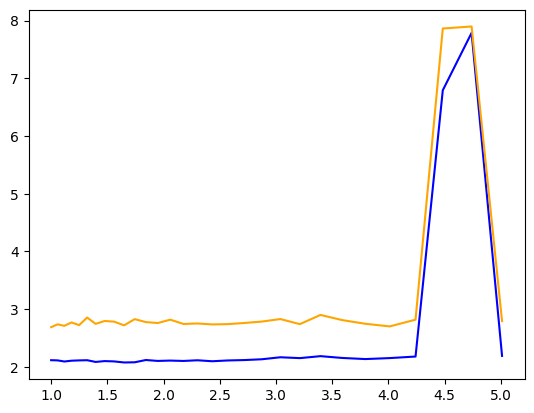

tensor(1.) 2.68768048286438
tensor(1.0572) 2.736813545227051
tensor(1.1176) 2.7108922004699707
tensor(1.1814) 2.7693932056427
tensor(1.2490) 2.7232348918914795
tensor(1.3204) 2.8547801971435547
tensor(1.3958) 2.7450649738311768
tensor(1.4756) 2.7949421405792236
tensor(1.5599) 2.7836787700653076
tensor(1.6491) 2.7194340229034424
tensor(1.7433) 2.8268632888793945
tensor(1.8430) 2.775608777999878
tensor(1.9483) 2.7592875957489014
tensor(2.0596) 2.818009376525879
tensor(2.1774) 2.742746114730835
tensor(2.3018) 2.752051830291748
tensor(2.4334) 2.7354772090911865
tensor(2.5724) 2.7407944202423096
tensor(2.7195) 2.7603325843811035
tensor(2.8749) 2.7849714756011963
tensor(3.0392) 2.828378677368164
tensor(3.2129) 2.740457057952881
tensor(3.3965) 2.899738073348999
tensor(3.5906) 2.810075044631958
tensor(3.7959) 2.746417760848999
tensor(4.0128) 2.7011475563049316
tensor(4.2422) 2.818131446838379
tensor(4.4846) 7.863673210144043
tensor(4.7409) 7.898697376251221
tensor(5.0119) 2.7939229011535645


In [12]:
plt.plot([r[0] for r in results], [r[1] for r in results],color="blue")
plt.plot(new_lr_list,dev_losses,color="orange")
plt.show()
for lr, loss in zip(new_lr_list,dev_losses):
    print(lr,loss)

In [15]:
model2 = MLP(emb_dim=3, hidden_size=100)

optimizer = torch.optim.SGD(
    model2.parameters(),
    lr=1.0
)

for i in range(15000):

    lr = (
        1.0 if i < 5000 else
        0.5 if i < 8000 else
        0.2 if i < 11000 else
        0.1
    )

    optimizer.param_groups[0]['lr'] = lr

    logits = model2(Xtr)
    loss = f.cross_entropy(logits, Ytr)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (i+1) % 300 == 0:
        print(loss.item())

2.2644920349121094
2.1694087982177734
2.1110832691192627
2.0721797943115234
2.048945426940918
2.033385992050171
2.016603708267212
2.0095012187957764
1.9978352785110474
1.9928309917449951
1.98585045337677
1.981059193611145
1.9759058952331543
1.974623441696167
1.9754210710525513
1.969180703163147
1.9485561847686768
1.9471460580825806
1.9459373950958252
1.944833755493164
1.9438061714172363
1.942838191986084
1.9419187307357788
1.9410386085510254
1.9402412176132202
1.9394185543060303
1.9387321472167969
1.9384163618087769
1.9381043910980225
1.937795877456665
1.9374923706054688
1.9371936321258545
1.9368993043899536
1.9366101026535034
1.936325192451477
1.936044692993164
1.9358140230178833
1.9356772899627686
1.9355415105819702
1.9354065656661987
1.9352728128433228
1.9351403713226318
1.9350082874298096
1.9348772764205933
1.934747338294983
1.9346178770065308
1.9344894886016846
1.9343616962432861
1.9342349767684937
1.9341092109680176


In [ ]:
#checking final loss on dev 

with torch.no_grad():
    logits=model2(Xdev)
    print(f.cross_entropy(logits,Ydev))




tensor(2.8723)


In [ ]:
import copy
import torch
import torch.nn.functional as F

model = MLP(emb_dim=3, hidden_size=100)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=1.0
)

best_dev_loss = float('inf')
best_model = None

lr_wait = 0
stop_wait = 0
lr_patience = 3
early_stop_patience = 8

for i in range(20000):

    # Training
    logits = model(Xtr)
    loss = F.cross_entropy(logits, Ytr)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Evaluate every 200 iterations
    if (i + 1) % 200 == 0:

        with torch.no_grad():
            train_loss = F.cross_entropy(model(Xtr), Ytr)
            dev_loss = F.cross_entropy(model(Xdev), Ydev)

        print(
            f"Step {i+1} | "
            f"LR {optimizer.param_groups[0]['lr']:.4f} | "
            f"Train {train_loss.item():.4f} | "
            f"Dev {dev_loss.item():.4f}"
        )

        # Check improvement
        if dev_loss.item() < best_dev_loss - 0.001:

            best_dev_loss = dev_loss.item()
            best_model = copy.deepcopy(model.state_dict())
            stop_weight=0
            lr_weight=0

        else:
            stop_wait+=1
            lr_wait+=1

        # Reduce LR if validation loss plateaus
        if lr_wait >= lr_patience:

            optimizer.param_groups[0]['lr'] *= 0.5
            print("Reducing learning rate!")

            # Reset patience after LR reduction
            lr_wait = 0

        # Early stopping
        # Simplified example: stop if validation doesn't improve
        # for 8 consecutive evaluation intervals.
        if stop_weight >= early_stop_patience:
            print("Early stopping!")
            break

# Restore best model
if best_model is not None:
    model.load_state_dict(best_model)


    # realised that model is overfitting  training loss is decreasing but dev loss isnt
    # for learning rate 1 , the learning loss and dev loss actually decreases for around 1000 iterations but after that it starts overfitting

Step 200 | LR 1.0000 | Train 2.3112 | Dev 2.6745
Step 400 | LR 1.0000 | Train 2.2249 | Dev 2.6897
Step 600 | LR 1.0000 | Train 2.1689 | Dev 2.6580
Step 800 | LR 1.0000 | Train 2.1273 | Dev 2.6647
Step 1000 | LR 1.0000 | Train 2.1000 | Dev 2.6553
Step 1200 | LR 1.0000 | Train 2.0750 | Dev 2.7183
Reducing learning rate!
Step 1400 | LR 0.5000 | Train 2.0539 | Dev 2.6972
Step 1600 | LR 0.5000 | Train 2.0457 | Dev 2.7078
Step 1800 | LR 0.5000 | Train 2.0384 | Dev 2.7170
Reducing learning rate!
Step 2000 | LR 0.2500 | Train 2.0350 | Dev 2.7211
Step 2200 | LR 0.2500 | Train 2.0318 | Dev 2.7250
Step 2400 | LR 0.2500 | Train 2.0287 | Dev 2.7286
Reducing learning rate!
Step 2600 | LR 0.1250 | Train 2.0272 | Dev 2.7302
Step 2800 | LR 0.1250 | Train 2.0258 | Dev 2.7319
Step 3000 | LR 0.1250 | Train 2.0244 | Dev 2.7335
Reducing learning rate!


KeyboardInterrupt: 

In [24]:
import copy
import torch
import torch.nn.functional as F

modelC = MLP(emb_dim=3, hidden_size=100)

optimizer = torch.optim.SGD(
    modelC.parameters(),
    lr=0.5
)

best_dev_loss = float('inf')
best_model = None

for i in range(3000):
    if(i==800):
        lr=0.25
    if(i==1500):
        lr=0.125
    if(i==2000):
        lr=0.05
    if(i==2500):
        lr=0.01

    loss=f.cross_entropy(modelC(Xtr),Ytr)
    with torch.no_grad():
        dev_loss=f.cross_entropy(modelC(Xdev),Ydev)
        if(best_dev_loss-0.001>dev_loss):
            best_model=copy.deepcopy(modelC.state_dict())
            best_dev_loss=dev_loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
if best_model is not None:
    modelC.load_state_dict(best_model)

print(best_dev_loss.item())



    





2.6489644050598145
